In [11]:
%pip install -e ..

Obtaining file:///C:/Users/V%C3%ADctorAguirreVargas/OneDrive%20-%20Kepler%20Group%20LLC/Documents/DS%26A/Data%20Science/Paycom%20Tests/Datascience-Stuff
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Using cached scikit-learn-extra-0.3.0.tar.gz (818 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.

  error: subprocess-exited-with-error
  
  × Building wheel for scikit-learn-extra (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [77 lines of output]
      C:\Users\VÃ­ctorAguirreVargas\AppData\Local\Temp\pip-build-env-3my9yoy9\overlay\Lib\site-packages\setuptools\dist.py:599: SetuptoolsDeprecationWarning: Invalid dash-separated key 'description-file' in 'metadata' (setup.cfg), please use the underscore name 'description_file' instead.
      !!
      
              ********************************************************************************
              Usage of dash-separated 'description-file' will not be supported in future
              versions. Please use the underscore name 'description_file' instead.
              (Affected: scikit-learn-extra).
      
              Available configuration options are listed in:
              https://setuptools.pypa.io/en/latest/userguide/declarative_config.html
      
              This deprecation is overdue, please u

In [12]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

from datascience_toolkit import (
    DFPreprocess,
    EDAQuick,
    UnsupervisedAnalysis,
    plot_radar_comparison,
    plot_embedding_clusters,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# No supervisado

In [13]:
df = pd.read_csv("../data/VirtualPatient.csv", sep=",")

In [14]:
df.head()

,gender,age,hospitalization_three_years,ortho_hypotension,vision,audition,exhaustion_score,balance_single,gait_get_up,gait_speed_4m,grip_strength_abnormal,bmi_score,anxiety_perception,life_quality,social_visits
0,M,78,0,No,Sees moderately,Hears moderately,1,>5 sec,9.05,8.80,No,24.095500,1.3,6.8,1
1,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,10.30,6.20,No,24.205693,1.7,7.2,999
2,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,9.40,7.20,No,24.576145,2.2,6.5,1
3,M,80,0,No,Sees moderately,Hears moderately,1,>5 sec,9.20,6.45,No,24.836407,4.8,6.9,1
4,F,72,3,No,Sees well,Hears well,1,>5 sec,9.80,4.70,No,23.437500,10.0,7.3,2


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       117 non-null    object 
 1   age                          117 non-null    int64  
 2   hospitalization_three_years  117 non-null    int64  
 3   ortho_hypotension            117 non-null    object 
 4   vision                       117 non-null    object 
 5   audition                     117 non-null    object 
 6   exhaustion_score             117 non-null    int64  
 7   balance_single               117 non-null    object 
 8   gait_get_up                  117 non-null    float64
 9   gait_speed_4m                117 non-null    float64
 10  grip_strength_abnormal       117 non-null    object 
 11  bmi_score                    117 non-null    float64
 12  anxiety_perception           117 non-null    float64
 13  life_quality        

In [16]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,117,2,M,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,117.0,NaN,NaN,NaN,76.726496,3.478069,70.0,74.0,77.0,79.0,85.0
hospitalization_three_years,117.0,NaN,NaN,NaN,0.598291,0.831076,0.0,0.0,0.0,1.0,3.0
ortho_hypotension,117,2,No,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vision,117,3,Sees well,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
audition,117,2,Hears well,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exhaustion_score,117.0,NaN,NaN,NaN,1.239316,0.428501,1.0,1.0,1.0,1.0,2.0
balance_single,117,3,>5 sec,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gait_get_up,117.0,NaN,NaN,NaN,18.719658,91.527393,4.0,7.43,9.05,11.8,999.0
gait_speed_4m,117.0,NaN,NaN,NaN,6.619915,3.556938,2.54,4.57,5.6,7.3,22.8


In [17]:
eda = EDAQuick(df)

eda.run_eda(
    show_corr=True,
    show_outliers=True,
    show_missing=True,
    show_cardinality=True,
    show_target=False,
    show_predictive_power=False
)

Columnas convertidas a category: ['gender', 'ortho_hypotension', 'vision', 'audition', 'balance_single', 'grip_strength_abnormal']
========== DATASET INFO ==========
rows: 117
cols: 15
memory_mb: 0.01
duplicates_rows: 0
target: None
n_numeric: 9
n_categorical: 6
n_datetime: 0
n_boolean: 0
n_other: 0

========== SUMMARY (top) ==========


,dtype,n_null,pct_null,n_unique,pct_unique
feature,,,,,
bmi_score,float64,0,0.0,104,88.8889
gait_get_up,float64,0,0.0,90,76.9231
gait_speed_4m,float64,0,0.0,77,65.8120
anxiety_perception,float64,0,0.0,44,37.6068
life_quality,float64,0,0.0,34,29.0598
age,int64,0,0.0,16,13.6752
social_visits,int64,0,0.0,10,8.5470
hospitalization_three_years,int64,0,0.0,4,3.4188
vision,category,0,0.0,3,2.5641



========== MISSING VALUES ==========
No se detectaron valores faltantes.

========== CARDINALITY ==========


,feature,dtype,n_unique,pct_unique,is_constant,is_high_cardinality,is_id_like
0,bmi_score,float64,104,88.8889,False,False,False
1,gait_get_up,float64,90,76.9231,False,False,False
2,gait_speed_4m,float64,77,65.8120,False,False,False
3,anxiety_perception,float64,44,37.6068,False,False,False
4,life_quality,float64,34,29.0598,False,False,False
5,age,int64,16,13.6752,False,False,False
6,social_visits,int64,10,8.5470,False,False,False
7,hospitalization_three_years,int64,4,3.4188,False,False,False
8,vision,category,3,2.5641,False,False,False
9,balance_single,category,3,2.5641,False,False,False



========== DESCRIBE (numeric) ==========


,count,mean,std,min,25%,50%,75%,max
age,117.0,76.7265,3.4781,70.0000,74.0000,77.0000,79.0000,85.000
hospitalization_three_years,117.0,0.5983,0.8311,0.0000,0.0000,0.0000,1.0000,3.000
exhaustion_score,117.0,1.2393,0.4285,1.0000,1.0000,1.0000,1.0000,2.000
gait_get_up,117.0,18.7197,91.5274,4.0000,7.4300,9.0500,11.8000,999.000
gait_speed_4m,117.0,6.6199,3.5569,2.5400,4.5700,5.6000,7.3000,22.800
bmi_score,117.0,28.6649,5.1872,22.4793,24.7444,27.1681,29.7888,44.658
anxiety_perception,117.0,4.5778,3.1077,0.0000,2.0000,4.0000,7.9000,10.000
life_quality,117.0,8.4906,1.5308,2.0000,8.0000,8.6000,10.0000,10.000
social_visits,117.0,38.3590,181.5341,0.0000,2.0000,5.0000,7.0000,999.000



========== CORRELATION ==========


No se detectaron pares con |correlación| >= 0.80.

========== OUTLIERS ==========


,feature,n,n_outliers,pct_outliers,lower_bound,upper_bound,min,max
0,exhaustion_score,117,28,23.9316,1.0000,1.0000,1.0000,2.000
1,gait_speed_4m,117,10,8.5470,0.4750,11.3950,2.5400,22.800
2,bmi_score,117,9,7.6923,17.1777,37.3555,22.4793,44.658
3,gait_get_up,117,7,5.9829,0.8750,18.3550,4.0000,999.000
4,hospitalization_three_years,117,6,5.1282,-1.5000,2.5000,0.0000,3.000
5,social_visits,117,4,3.4188,-5.5000,14.5000,0.0000,999.000
6,life_quality,117,4,3.4188,5.0000,13.0000,2.0000,10.000
7,age,117,0,0.0000,66.5000,86.5000,70.0000,85.000
8,anxiety_perception,117,0,0.0000,-6.8500,16.7500,0.0000,10.000


,gender,age,hospitalization_three_years,ortho_hypotension,vision,audition,exhaustion_score,balance_single,gait_get_up,gait_speed_4m,grip_strength_abnormal,bmi_score,anxiety_perception,life_quality,social_visits
0,M,78,0,No,Sees moderately,Hears moderately,1,>5 sec,9.05,8.80,No,24.095500,1.3,6.8,1
1,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,10.30,6.20,No,24.205693,1.7,7.2,999
2,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,9.40,7.20,No,24.576145,2.2,6.5,1
3,M,80,0,No,Sees moderately,Hears moderately,1,>5 sec,9.20,6.45,No,24.836407,4.8,6.9,1
4,F,72,3,No,Sees well,Hears well,1,>5 sec,9.80,4.70,No,23.437500,10.0,7.3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,F,75,0,No,Sees well,Hears well,1,<5 sec,6.30,3.80,Yes,35.430839,5.0,8.0,7
113,F,78,0,No,Sees well,Hears moderately,2,>5 sec,15.00,18.00,Yes,34.484158,8.0,9.0,7
114,F,78,0,No,Sees well,Hears moderately,1,<5 sec,12.00,15.00,Yes,35.295550,5.0,10.0,7
115,F,78,0,No,Sees well,Hears moderately,1,<5 sec,15.00,18.00,Yes,35.295550,3.0,10.0,7


In [18]:
eda.skewness_report()

,column,skewness,status,recommended_transform
0,gait_get_up,10.774,Highly Skewed,Log / Box-Cox
1,social_visits,5.192,Highly Skewed,Yeo-Johnson
2,gait_speed_4m,2.363,Highly Skewed,Log / Box-Cox
3,hospitalization_three_years,1.423,Highly Skewed,Yeo-Johnson
4,life_quality,-1.410,Highly Skewed,Log / Box-Cox
5,bmi_score,1.326,Highly Skewed,Log / Box-Cox
6,exhaustion_score,1.238,Highly Skewed,Log / Box-Cox
7,anxiety_perception,0.237,Symmetric,None
8,age,0.201,Symmetric,None


In [19]:
import inspect
from datascience_toolkit.preprocessing import DFPreprocess

print(inspect.signature(DFPreprocess.__init__))

(self, scale_num: str = 'standard', num_impute: str = 'median', cat_impute: str = 'most_frequent', encoding: str = 'ordinal')


# CLusterizacion

In [20]:
uns = UnsupervisedAnalysis(df)

prep = uns.prepare(
    scale_num="auto",
    cat_encoding="auto"
)

✓ DATA PREPARATION SUMMARY
- Filas procesadas:        117
- Columnas originales:     15
- Características finales: 23 (tras encoding)
- Estrategia de escalado:  standard
- Codificación categórica: onehot


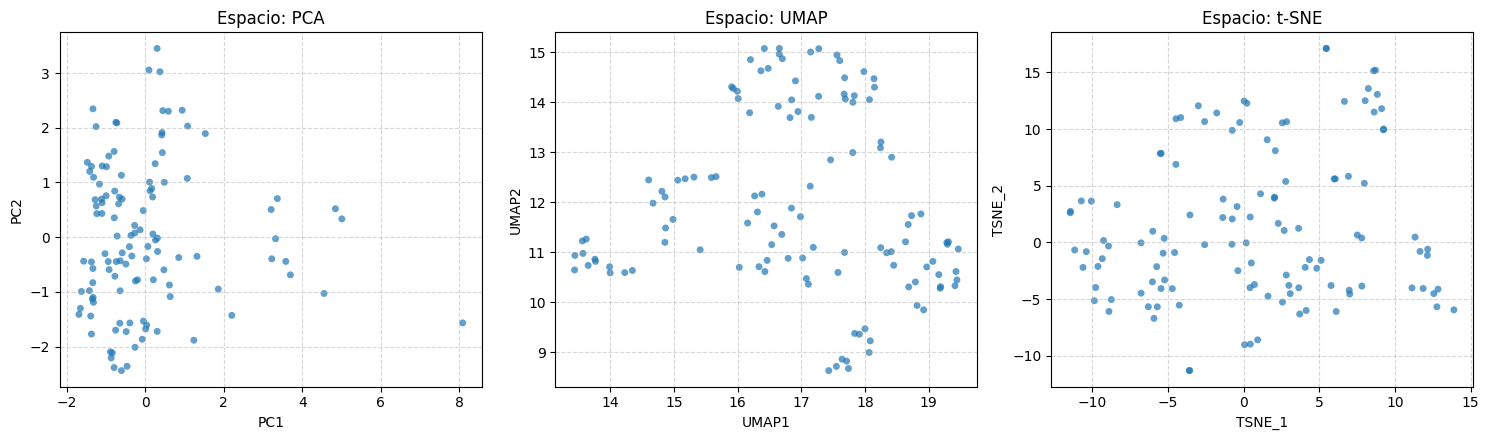

,embedding,method,n_components,variance_explained,parameters,purpose,status
0,pca_visual,pca,2,0.372765,"svd_solver=auto, whiten=False",visualization,created
1,pca_model,pca,11,0.915989,target_variance=0.9,clustering candidate,created
2,umap_visual,umap,2,NaN,"n_neighbors=15, min_dist=0.1, metric=euclidean",visualization / local structure,created


In [21]:
exploration = uns.explore(
    methods=("pca", "umap", "tsne"),
    pca_model_variance=0.90,
    umap_params={
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "euclidean",
    },
    tsne_params={
        "perplexity": 20,
        "learning_rate": "auto",
        "max_iter": 1000,
        "init": "pca",
        "metric": "euclidean",
    },
    plot=True,
)

exploration["report"]

In [22]:
comparison = uns.compare_spaces(
    spaces=[
        "embed",
        "pca_model",
        "umap_visual"
    ],
    method="kmeans",
    k_range=range(2, 11),
    n_init=50,
    max_iter=500,
    tol=1e-4,
    random_state=42
)

comparison["leaderboard"]


========== SPACE COMPARISON INTERPRETATION ==========
- Configuración óptima global: Espacio 'umap_visual' con k=6 (Silhouette: 0.5662, Davies-Bouldin: 0.5588).
- Espacio 'umap_visual': Mejor balance en k=6 (Silueta: 0.5662).
- Espacio 'pca_model': Mejor balance en k=2 (Silueta: 0.3844).
- Espacio 'embed': Mejor balance en k=2 (Silueta: 0.3636).


,space,method,best_k,silhouette,calinski_harabasz,davies_bouldin,inertia,n_iter,converged,consensus_rank
0,umap_visual,kmeans,6,0.566157,211.632324,0.558817,63.425354,4,True,1.0
1,pca_model,kmeans,2,0.384421,24.233537,1.390417,1015.480541,3,True,2.0
2,embed,kmeans,2,0.363597,21.891577,1.478827,1127.582441,2,True,3.0


# Vamos a comparar metodos de clustering

In [23]:
uns.available_cluster_models() #vemos que metodos tenemos, en notas sale si hace falta alguno

pd.set_option("display.max_colwidth", None)

In [24]:
recommendations = uns.recommend_cluster_models(
    X="pca_model"
)

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(recommendations)

,algorithm,suitability,rationale,suggested_params
0,K-Means,Highly Recommended,Excelente línea base para 117 muestras y 11 dimensiones. Supone clústeres globulares/esféricos de varianza similar.,"k: range(2, 8), n_init=20 o 50"
1,Agglomerative (Hierarchical),Highly Recommended,Ideal para datasets pequeños a medianos (n=117). Permite descubrir jerarquías taxonómicas sin fijar k de antemano y no sufre de convergencia local.,"linkage='ward', metric='euclidean'"
2,Gaussian Mixture Models (GMM),Recommended,Permite clústeres elipsoidales con asignación probabilística suave (soft clustering). Relación muestras/variables (117/11) adecuada.,"covariance_type='diag' si d es alto, n_components: 2-6"
3,DBSCAN,Recommended,Capaz de encontrar formas no esféricas y aislar ruido/outliers. Con 11 dimensiones la distancia euclidiana aún mantiene contraste espacial.,"min_samples=11, calibrar eps con gráfica de k-distancias"
4,HDBSCAN,Recommended,Supera a DBSCAN al tolerar densidades variables y seleccionar clusters estables automáticamente a lo largo de un árbol jerárquico.,min_cluster_size=5


# Experimentos

In [25]:
experiment = uns.build_experiment(
    spaces=["embed", "pca_model"],
    models="recommended",
    k_range=range(2, 11),

    evaluate_stability=True,
    n_stability_runs=5,

    n_init=50,
    max_iter=500,
    tol=1e-4,

    #random_state=42,
    #master_seed=123
)

========== CLUSTERING EXPERIMENT PLAN ==========


,step,role,model,priority_label,available,reason,experiment_purpose
0,1,baseline,kmeans,Exploratory,True,baseline interpretable,"Establish a fast, interpretable centroid benchmark."
1,2,robust alternative,kmedoids,High,True,costo viable para este tamaño - se detectaron variables robust-scaled/outliers,Test a medoid solution that is less sensitive to extreme observations.
2,3,hierarchical alternative,agglomerative,Recommended,True,dataset pequeño/mediano,Test whether a nested or linkage-based structure better represents the sample.
3,4,probabilistic alternative,gaussian_mixture,Exploratory,True,evalúa pertenencia probabilística,Test elliptical clusters and soft membership probabilities.
4,5,density/noise diagnostic,dbscan,Caution,True,puede identificar observaciones aisladas - muestra suficiente para explorar densidad,Test irregular shapes and whether isolated observations should be treated as noise.
5,6,variable-density diagnostic,hdbscan,Exploratory,True,puede explorar densidades variables,Explore density-varying groups and noise without fixing k.


Note: this is a test plan, not a model ranking. Use plan.run() for the competition.



In [26]:
exp = experiment.plan()

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(exp)


c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `c

,role,space,model,k,silhouette,davies_bouldin,stability,strategic_rationale,next_action
0,Primary Champion,pca_model,kmeans,10,0.247192,1.039405,0.763190,"Mayor puntuación global en el torneo (Score: 17.2, Silueta: 0.2472).",Proceder a perfilamiento de arquetipos y análisis de medias por clúster.
1,Stability Champion,pca_model,kmedoids,10,0.208805,1.260810,1.000000,Máxima consistencia (ARI: 1.0000).,Usar si la reproducibilidad en producción es prioritaria sobre la separación pura.
2,Compactness Champion,pca_model,dbscan,2,0.357839,0.800328,1.000000,Mínima dispersión intra-clúster (DB: 0.8003).,Examinar fronteras de decisión y dispersión de outliers.
3,Runner-up (#4),pca_model,kmeans,9,0.229185,1.155334,0.765505,Candidato competitivo con silueta 0.2292.,Considerar como alternativa de respaldo.
4,Runner-up (#5),pca_model,kmeans,8,0.222111,1.206538,0.840926,Candidato competitivo con silueta 0.2221.,Considerar como alternativa de respaldo.


In [27]:
experiment.explain()

📊 CLUSTERING EXPERIMENT DIAGNOSIS & INTERPRETATION

1. CONFIGURACIÓN GANADORA (CHAMPION)
   - Espacio vectorial:   pca_model
   - Familia de modelo:   KMEANS
   - Número de clusters:  k = 10
   - Silhouette Score:    0.2472
   - Davies-Bouldin:      1.0394
   - Estabilidad (ARI):   0.7632


In [28]:
competition = experiment.run()

========== CLUSTERING COMPETITION ==========


,rank,space,model,params,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_pct,min_cluster_pct,run_key,competition_score
0,1,pca_model,kmeans,"{'k': 10, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",10,0.247192,24.661268,1.039405,0.763190,0.0,0.854701,pca_model__kmeans__k10,17.2
1,2,pca_model,kmeans,"{'k': 9, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",9,0.229185,24.718345,1.155334,0.765505,0.0,0.854701,pca_model__kmeans__k9,18.6
2,3,pca_model,kmeans,"{'k': 8, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",8,0.222111,24.741579,1.206538,0.840926,0.0,0.854701,pca_model__kmeans__k8,19.0
3,4,pca_model,kmedoids,"{'k': 10, 'metric': 'euclidean', 'max_iter': 500, 'random_state': 42}",10,0.208805,21.960814,1.260810,1.000000,0.0,0.854701,pca_model__kmedoids__euclidean__k10,19.2
4,5,pca_model,kmeans,"{'k': 2, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",2,0.384421,24.233537,1.390417,0.905375,0.0,10.256410,pca_model__kmeans__k2,19.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,101,embed,gaussian_mixture,"{'k': 3, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",3,0.067797,6.094335,3.401115,0.633943,0.0,9.401709,embed__gaussian_mixture__diag__k3,76.8
101,102,embed,gaussian_mixture,"{'k': 7, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",7,0.072359,9.495539,2.349049,0.389653,0.0,3.418803,embed__gaussian_mixture__diag__k7,78.6
102,103,embed,gaussian_mixture,"{'k': 6, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",6,0.043037,9.346750,2.432011,0.361308,0.0,3.418803,embed__gaussian_mixture__diag__k6,80.6
103,104,embed,gaussian_mixture,"{'k': 5, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",5,0.024806,8.749562,2.699077,0.381205,0.0,0.854701,embed__gaussian_mixture__diag__k5,81.6


In [29]:
comp = competition.leaderboard()

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(comp)

,rank,space,model,params,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_pct,min_cluster_pct,run_key,competition_score
0,1,pca_model,kmeans,"{'k': 10, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",10,0.247192,24.661268,1.039405,0.763190,0.0,0.854701,pca_model__kmeans__k10,17.2
1,2,pca_model,kmeans,"{'k': 9, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",9,0.229185,24.718345,1.155334,0.765505,0.0,0.854701,pca_model__kmeans__k9,18.6
2,3,pca_model,kmeans,"{'k': 8, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",8,0.222111,24.741579,1.206538,0.840926,0.0,0.854701,pca_model__kmeans__k8,19.0
3,4,pca_model,kmedoids,"{'k': 10, 'metric': 'euclidean', 'max_iter': 500, 'random_state': 42}",10,0.208805,21.960814,1.260810,1.000000,0.0,0.854701,pca_model__kmedoids__euclidean__k10,19.2
4,5,pca_model,kmeans,"{'k': 2, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",2,0.384421,24.233537,1.390417,0.905375,0.0,10.256410,pca_model__kmeans__k2,19.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,101,embed,gaussian_mixture,"{'k': 3, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",3,0.067797,6.094335,3.401115,0.633943,0.0,9.401709,embed__gaussian_mixture__diag__k3,76.8
101,102,embed,gaussian_mixture,"{'k': 7, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",7,0.072359,9.495539,2.349049,0.389653,0.0,3.418803,embed__gaussian_mixture__diag__k7,78.6
102,103,embed,gaussian_mixture,"{'k': 6, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",6,0.043037,9.346750,2.432011,0.361308,0.0,3.418803,embed__gaussian_mixture__diag__k6,80.6
103,104,embed,gaussian_mixture,"{'k': 5, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",5,0.024806,8.749562,2.699077,0.381205,0.0,0.854701,embed__gaussian_mixture__diag__k5,81.6


In [30]:
comp = competition.leaderboard()

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(comp)

,rank,space,model,params,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_pct,min_cluster_pct,run_key,competition_score
0,1,pca_model,kmeans,"{'k': 10, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",10,0.247192,24.661268,1.039405,0.763190,0.0,0.854701,pca_model__kmeans__k10,17.2
1,2,pca_model,kmeans,"{'k': 9, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",9,0.229185,24.718345,1.155334,0.765505,0.0,0.854701,pca_model__kmeans__k9,18.6
2,3,pca_model,kmeans,"{'k': 8, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",8,0.222111,24.741579,1.206538,0.840926,0.0,0.854701,pca_model__kmeans__k8,19.0
3,4,pca_model,kmedoids,"{'k': 10, 'metric': 'euclidean', 'max_iter': 500, 'random_state': 42}",10,0.208805,21.960814,1.260810,1.000000,0.0,0.854701,pca_model__kmedoids__euclidean__k10,19.2
4,5,pca_model,kmeans,"{'k': 2, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",2,0.384421,24.233537,1.390417,0.905375,0.0,10.256410,pca_model__kmeans__k2,19.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,101,embed,gaussian_mixture,"{'k': 3, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",3,0.067797,6.094335,3.401115,0.633943,0.0,9.401709,embed__gaussian_mixture__diag__k3,76.8
101,102,embed,gaussian_mixture,"{'k': 7, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",7,0.072359,9.495539,2.349049,0.389653,0.0,3.418803,embed__gaussian_mixture__diag__k7,78.6
102,103,embed,gaussian_mixture,"{'k': 6, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",6,0.043037,9.346750,2.432011,0.361308,0.0,3.418803,embed__gaussian_mixture__diag__k6,80.6
103,104,embed,gaussian_mixture,"{'k': 5, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",5,0.024806,8.749562,2.699077,0.381205,0.0,0.854701,embed__gaussian_mixture__diag__k5,81.6


In [31]:
solution = uns.cluster_kmeans(
    X="pca_model",
    k=3,
    n_init=100,
    max_iter=1000,
    tol=1e-5,
    #random_state=42,
    name="virtual_patient_segments"
)

✓ K-MEANS SOLUTION FITTED: 'virtual_patient_segments'
- Espacio vectorial:   pca_model (11 dimensiones)
- Número de clústeres: k = 3
- Silhouette Score:    0.1743
- Davies-Bouldin:      1.7635
- Calinski-Harabasz:   23.66
- Distribución:        {0: np.int64(12), 1: np.int64(57), 2: np.int64(48)}


In [32]:
solution.summary()

,count,percentage
virtual_patient_segments,,
0,12,10.26
1,57,48.72
2,48,41.03


In [33]:
clust_df =solution.dataset()

In [34]:
clust_df['cluster'].value_counts()

cluster
1    57
2    48
0    12
Name: count, dtype: int64

In [35]:
solution.describe(top_n=5, min_abs_z=0.4)

📋 DISTINCTIVE CLUSTER PROFILES (Z-SCORE DIFFERENTIAL)

🔹 Clúster 0 (12 observaciones, 10.3%):
   ▲ gait_speed_4m             | z = +2.22 | Clúster: 14.492 (Global: 6.62)
   ▲ bmi_score                 | z = +2.10 | Clúster: 39.49 (Global: 28.665)
   ▲ exhaustion_score          | z = +1.39 | Clúster: 1.833 (Global: 1.239)
   ▲ age                       | z = +0.97 | Clúster: 80.083 (Global: 76.726)
   ▲ gait_get_up               | z = +0.90 | Clúster: 101.083 (Global: 18.72)

🔹 Clúster 1 (57 observaciones, 48.7%):
   ▼ anxiety_perception        | z = -0.79 | Clúster: 2.121 (Global: 4.578)
   ▲ life_quality              | z = +0.51 | Clúster: 9.272 (Global: 8.491)
   ▲ age                       | z = +0.46 | Clúster: 78.333 (Global: 76.726)

🔹 Clúster 2 (48 observaciones, 41.0%):
   ▲ anxiety_perception        | z = +0.81 | Clúster: 7.096 (Global: 4.578)
   ▼ age                       | z = -0.79 | Clúster: 73.979 (Global: 76.726)
   ▼ life_quality              | z = -0.56 | Clúster: 7.6

,cluster,feature,cluster_mean,global_mean,z_score,direction
0,0,gait_speed_4m,14.492,6.620,2.223,High (+)
1,0,bmi_score,39.490,28.665,2.096,High (+)
2,0,exhaustion_score,1.833,1.239,1.392,High (+)
3,0,age,80.083,76.726,0.969,High (+)
4,0,gait_get_up,101.083,18.720,0.904,High (+)
5,1,anxiety_perception,2.121,4.578,-0.794,Low (-)
6,1,life_quality,9.272,8.491,0.513,High (+)
7,1,age,78.333,76.726,0.464,High (+)
8,2,anxiety_perception,7.096,4.578,0.814,High (+)
9,2,age,73.979,76.726,-0.793,Low (-)


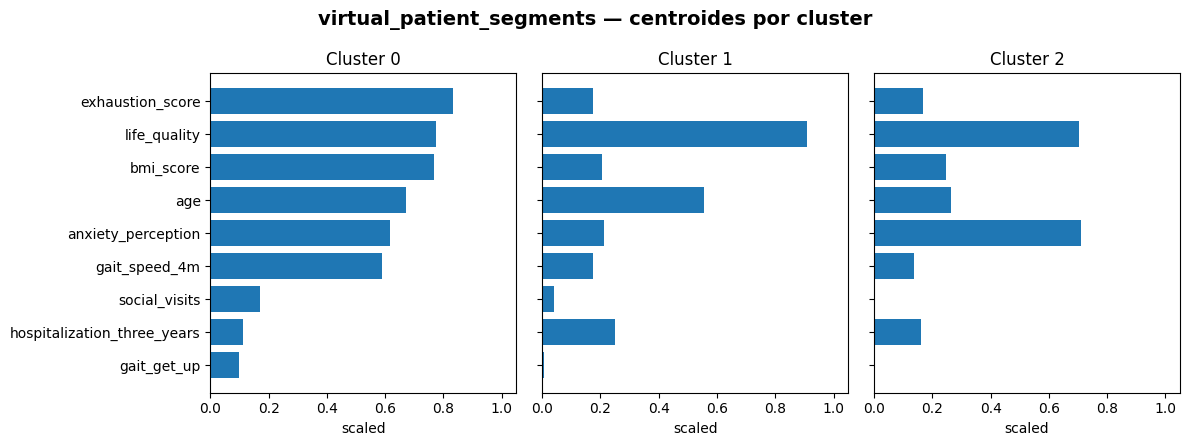

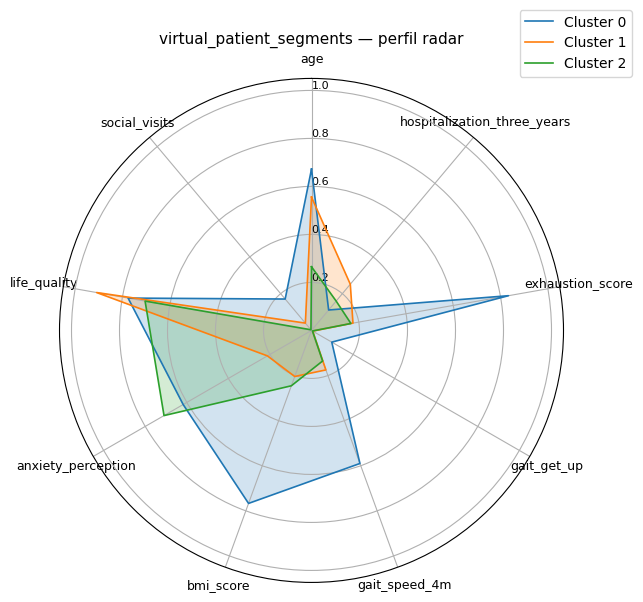

In [36]:

solution.plot_cluster_bars(normalize=True)
solution.plot_cluster_radar(normalize="minmax")